# Contextual Lexical-Stress Prediction for Bulgarian TTS from Dictionary-Marked Text and Stress-Aware Forced Alignment

**A reproduction and extension of the Accentor front-end (Geneva et al., Interspeech 2023), integrated into a diffusion-LM TTS (OmniVoice)**

*Draft paper foundation — OmniVoice-BG project, 2026. All tables and figures in this notebook regenerate from the repository's real experiment artifacts.*

---

## Abstract *(draft)*

Bulgarian lexical stress is phonemic, mobile, and unmarked in orthography; roughly 1 in 23 word forms is a stress **homograph** (въ́лна *wool* / вълна́ *wave*), and ~34% of utterances contain at least one. Dictionary lookup cannot resolve homographs, and synthetic-speech oracles systematically fail on them. We reproduce the Accentor architecture — a character-level FFT-block network that marks the stressed vowel of every word in context — and train it **without any manually stress-annotated sentences**, using two label sources: (i) dictionary-marked text with homographs masked from the loss (pretrain, 80M tokens), and (ii) per-token stress choices decoded from human speech by a stress-aware Kaldi forced aligner over audiobooks and parliamentary recordings (fine-tune). A native-speaker vetting protocol calibrates a three-tier label-acceptance policy that neutralizes a systematic final-stress bias we identify in GMM alignment. We further introduce rule-assisted *both-readings* text mining for the morphologically regular imperative/3sg alternation. The resulting model reaches **0.002% stress-error rate** on held-out single-stress words and **0.014–0.021% out-of-domain SER** on parliamentary stenograms, with homograph-battery accuracy improving from 11/25 (text-only) to 13/25 and both readings of the highest-coverage homograph classes resolved contextually. We report empirical *coverage walls* for homograph learning — a ~20-distinct-contexts threshold per reading, an absolute-count (not class-ratio) wall for imperatives, and a demonstration that sparse noisy minority labels *invert* classes — and integrate the front-end into OmniVoice-BG, showing that TTS stress control requires the acoustic model to be fine-tuned on the *same* marking function it sees at inference.

> **TODO before submission:** exact bibliographic entries (§References), final OOD numbers after the milestone-A data lands, MOS/listening-test protocol for §8.


## Contents

1. [Introduction](#1.-Introduction)
2. [Background and related work](#2.-Background-and-related-work)
3. [System overview: a three-model relay](#3.-System-overview:-a-three-model-relay)
4. [Data](#4.-Data)
5. [Method](#5.-Method)
6. [Experiments and results](#6.-Experiments-and-results)
7. [Findings](#7.-Findings)
8. [End-to-end TTS evaluation](#8.-End-to-end-TTS-evaluation)
9. [Limitations](#9.-Limitations)
10. [Future work](#10.-Future-work)
11. [Reproducibility](#11.-Reproducibility)
12. [References](#12.-References)


In [1]:
# Setup — all paths resolve relative to the repo root (notebook lives in docs/)
import json, os, sys, sqlite3, collections, random
from pathlib import Path

ROOT = Path('.') if Path('exp').exists() else Path('..')
assert (ROOT / 'accentor_model.py').exists(), 'run from the OmniVoice repo (or docs/)'

def jload(path, limit=None):
    "Read a JSONL file -> list of dicts (optionally first `limit` rows)."
    rows = []
    with open(ROOT / path, encoding='utf-8') as f:
        for i, line in enumerate(f):
            if limit and i >= limit: break
            line = line.strip()
            if line: rows.append(json.loads(line))
    return rows

def exists(path): return (ROOT / path).exists()

import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams['figure.dpi'] = 110
print('repo root:', ROOT.resolve())

repo root: /home/preslaff/WORK/OmniVoice


## 1. Introduction

Bulgarian word stress is **lexical** (a property of the word, not the phrase), **mobile** (it moves within inflectional paradigms: чета́ *I read* → че́теш *you read*), **phonemic** (it distinguishes meanings), and **orthographically unmarked**. For a text-to-speech system this is the single hardest front-end problem in the language: the correct output depends on information that is simply not in the input string.

Three failure classes motivate this work, in increasing order of difficulty:

1. **Unknown words.** A TTS model with no stress knowledge guesses — *БУтона* for *буто́на*, *натИснете* for *натисне́те*. A pronunciation dictionary solves this for in-vocabulary words.
2. **Out-of-vocabulary inflections.** Bulgarian inflection is rich; a lemma dictionary must be *projected* onto ~2.5M inflected forms, with morphophonological rules for stress-shifting paradigms.
3. **Homographs.** Pairs like въ́лна/вълна́ (*wool/wave*), че́та/чета́ (*detachment/I read*), гово́ри/говори́ (*speaks/speak!*) are identical strings whose stress depends on **sentence context**. No dictionary can resolve them. Per Geneva et al., ~4.3% of Bulgarian word forms are stress-ambiguous and ~34% of utterances contain at least one.

The Accentor approach (Geneva et al., Interspeech 2023) treats stress placement as a **sequence-labeling problem over characters**: a lightweight network reads the whole sentence and emits, for every vowel, the probability that it carries its word's stress. Crucially, its training labels for ambiguous words can be manufactured **from speech** — a stress-aware forced aligner, given both possible pronunciations of a homograph, decodes *which one the human actually said* — so no manual sentence-level stress annotation is ever needed.

This notebook documents a full reproduction of that recipe for a production Bulgarian TTS (OmniVoice-BG), plus what we learned that the original paper does not report.

### Contributions

- **C1 — A fully open, reproducible pipeline** from raw dictionary dump + book archive + parliamentary video API to a deployed contextual stress front-end, with no manually stress-annotated training sentences anywhere in the loop.
- **C2 — A recall-oriented multi-stress candidates lexicon** (2.16M candidate pronunciations; 84K ambiguous forms) built from the *rechko* dictionary, with a native-curated homograph battery and an always-final imperative override table correcting systematic dictionary errors.
- **C3 — A vetting-calibrated three-tier label policy** for alignment-derived stress labels, motivated by a systematic **final-stress bias** we identify in GMM forced alignment on prosodically weak words — strong enough to invert corpus majorities (може́ counted 1125:517 against the true мо́же).
- **C4 — Rule-assisted *both-readings* text mining** for the morphologically regular imperative/3sg alternation, which supplements speech labels for the register-starved imperative class at ~96% precision.
- **C5 — Empirical coverage laws for homograph learning:** a ~20-distinct-contexts-per-reading threshold; an *absolute-count* (not class-ratio) wall for imperfective imperatives; and a demonstration that sparse noisy minority labels can *invert* a class ("a little noisy data is worse than none").
- **C6 — End-to-end TTS integration** into a mask-prediction diffusion LM (OmniVoice), establishing the *marking-consistency principle*: the acoustic model must be fine-tuned on text marked by the same front-end version used at inference, or the mark→stress mapping it learns is noise.


## 2. Background and related work

**The Accentor (Geneva et al., Interspeech 2023).** The reference work. A character-level model (embedding + 6 FastSpeech-style FFT blocks + convolutional predictor, ~6.5M params with depthwise-separable convolutions) predicts per-vowel stress probabilities, trained with per-vowel BCE. Labels come from two sources: an authoritative stress dictionary for unambiguous words, and forced alignment of 749 h of speech (audiobooks + the BG-PARLAMA parliamentary corpus, 2,695 aligned hours) with a stressed/unstressed vowel phone set for ambiguous words. Reported stress-error rates: 0.119% (automatic) / 0.37% (manual evaluation).

**BG-PARLAMA.** Geneva et al.'s parliamentary speech corpus, built by aligning plenary-session video against the official stenographic transcripts. Our stage-4 crawl reproduces this resource from the same public source (parliament.bg pl-sten API), 2020–2026 sessions.

**Parliament-speech alignment pipelines.** Our long-audio segmentation follows the Kaldi `segment_long_utterances` recipe family used by the Finnish Parliament ASR corpus (Virkkunen et al., arXiv:2203.14876), which is the closest published engineering reference for transcript-biased decoding of plenary recordings.

**OmniVoice.** A massively multilingual zero-shot TTS: a Qwen3-0.6B text-LLM backbone repurposed to predict Higgs Audio V2 codec tokens (8 codebooks, 24 kHz) under a mask-prediction / iterative-denoising objective with classifier-free guidance. Voice cloning is an in-context acoustic prompt (reference audio + transcript prefix). OmniVoice renders explicit U+0301 stress marks — *if* it has been fine-tuned on marked text (§5.7, §8).

**Why not an end-to-end text→speech shortcut?** Stress *placement* is a linguistic decision trainable on billions of cheap text tokens; stress *acoustics* is a rendering problem needing aligned audio. Decoupling them — the paper's core thesis, which we confirm — buys contextual homograph correctness and zero-shot cloning simultaneously. A 38M-param end-to-end Bulgarian TTS (BgTTS-38M-V2) does place stress correctly from plain text on *unambiguous* words, but when tested as a stress oracle it failed **systematically on homographs**, always choosing the frequency-prior reading regardless of context (§7-F6) — synthetic speech must never label ambiguous forms.


## 3. System overview: a three-model relay

The system is a relay of three specialists. Only the two ends ever touch audio; the Accentor itself is text-only.

```
                 ┌────────────────────────────────────────────────────────┐
    TRAINING     │                                                        │
                 ▼                                                        │
  Kaldi acoustic model ──hears stress in human speech──▶ per-token stress labels
  (ANALYSIS: stressed/unstressed vowel phones a1/a0)              │
                                                                  ▼
  Accentor ◀────────────trained on those labels────  learns WHERE stress goes
  (PLACEMENT: text→text, chars in / U+0301 out; never sees a waveform)
                                                                  │
    INFERENCE                                                     ▼
  plain Bulgarian text ──▶ Accentor ──▶ marked text ──▶ OmniVoice-BG ──▶ 24 kHz audio
                                                        (SYNTHESIS: renders the
                                                         mark as acoustic stress)
```

1. **Kaldi acoustic model (analysis).** The only model that learns *how a stressed vowel sounds*: the phone set separates stressed from unstressed vowels (`a1`/`a0`, `o1`/`o0`, …), so during forced alignment the aligner must *choose* between a word's candidate pronunciations — effectively decoding which vowel the speaker stressed. This model **manufactures the training labels** (GMM ladder `mono→tri1→tri2b→tri3b SAT` in the pilots; an annotation TDNN at scale).
2. **Accentor (placement).** Character-level classifier: plain text in, per-vowel stress probabilities out, one U+0301 combining acute placed after the argmax vowel of each word (when confident). Learns *where* stress falls from surrounding words (чета́ кни́га vs въоръже́на че́та).
3. **OmniVoice-BG (synthesis).** The production TTS, fine-tuned on Accentor-marked transcripts so it learns U+0301 → acoustic stress correlates (duration, F0, energy). Serves TrainGen over a LAN FastAPI endpoint with deterministic fixed-voice cloning.

The **serving path** (`omnivoice/cli/serve.py`) supports two interchangeable stress front-ends: the dictionary lookup (`--lexicon`, rechko sqlite + overrides — the pre-Accentor baseline) and the contextual model (`--accentor <ckpt>`, which supersedes the lexicon). A human-curated overrides JSON remains the final veto in both configurations.


## 4. Data

Five resources feed the pipeline. None contains manual sentence-level stress annotation.

| Resource | Role | Scale |
|---|---|---|
| **rechko** dictionary dump | authoritative lemma stress → candidates lexicon | ~115K lemmas → 2.16M candidate pronunciations |
| **chitanka** book archive | pretrain text corpus (fiction, dialogue-rich) | 8,002 books → 6.0M sentences / 80M tokens |
| **Parliament crawl** (parliament.bg pl-sten API) | in-domain speech + stenographic transcripts | 81 sessions / 258 h banked (2020–2026 crawl running) |
| **Audiobooks** (single female narrator, 24 kHz) | alignment pilot + TTS fine-tune audio | 63 h aligned in pilot; ~400 h dataset ingesting |
| **Native-speaker curation** | homograph battery, function words, vetting verdicts | 25-item battery; 43 clitics; ~190 vetting judgments |


In [2]:
# Table 1 — live corpus inventory (regenerates from the working tree)
inv = []

# lexicon
if exists('data/bg_lexicon/bg_stress_candidates.sqlite'):
    con = sqlite3.connect(ROOT / 'data/bg_lexicon/bg_stress_candidates.sqlite')
    n_cand = con.execute('select count(*) from candidates').fetchone()[0]
    try:
        n_forms = con.execute('select count(distinct word) from candidates').fetchone()[0]
        n_ambig = con.execute(
            'select count(*) from (select word from candidates group by word having count(*)>1)'
        ).fetchone()[0]
    except sqlite3.OperationalError:  # column naming differs
        n_forms = n_ambig = None
    inv.append(('stress-candidates lexicon', f'{n_cand:,} pronunciations'
                + (f' / {n_forms:,} forms / {n_ambig:,} ambiguous' if n_forms else '')))
    con.close()

# chitanka marked corpus
if exists('data/chitanka/marked.jsonl'):
    n = sum(1 for _ in open(ROOT / 'data/chitanka/marked.jsonl', encoding='utf-8'))
    inv.append(('chitanka marked.jsonl (pretrain)', f'{n:,} sentences'))

# parliament
if exists('data/bg_parliament/manifest.jsonl'):
    rows = jload('data/bg_parliament/manifest.jsonl')
    hrs = sum(float(r['duration']) for r in rows) / 3600
    inv.append(('parliament sessions (crawled)', f'{len(rows)} sessions / {hrs:.0f} h'))

# speech stress labels
for p, name in [('data/kaldi/stress_labels.jsonl', 'audiobook stress labels (tri3b)'),
                ('data/kaldi/stress_labels_parliament2.jsonl', 'parliament stress labels (round 2)')]:
    if exists(p):
        n = sum(1 for _ in open(ROOT / p, encoding='utf-8'))
        inv.append((name, f'{n:,} tokens'))

# mined homograph contexts
if exists('data/chitanka/homograph_contexts.jsonl'):
    n = sum(1 for _ in open(ROOT / 'data/chitanka/homograph_contexts.jsonl', encoding='utf-8'))
    inv.append(('mined homograph contexts (text)', f'{n:,} sentences'))

# fine-tune mix
if exists('data/accentor_finetune.jsonl'):
    n = sum(1 for _ in open(ROOT / 'data/accentor_finetune.jsonl', encoding='utf-8'))
    inv.append(('Accentor fine-tune mix', f'{n:,} rows'))

# audiobooks-400h ingest
if exists('data/bg400/train.jsonl'):
    n = sum(1 for _ in open(ROOT / 'data/bg400/train.jsonl', encoding='utf-8'))
    n += sum(1 for _ in open(ROOT / 'data/bg400/dev.jsonl', encoding='utf-8'))
    inv.append(('audiobook clips ingested (bg400)', f'{n:,} clips'))

w = max(len(a) for a, _ in inv)
print('Table 1 — corpus inventory (live)\n' + '─' * (w + 40))
for a, b in inv:
    print(f'{a:<{w}}  {b}')

Table 1 — corpus inventory (live)
──────────────────────────────────────────────────────────────────────────
stress-candidates lexicon           2,163,560 pronunciations
chitanka marked.jsonl (pretrain)    7,058,735 sentences
parliament sessions (crawled)       81 sessions / 258 h
audiobook stress labels (tri3b)     168,531 tokens
parliament stress labels (round 2)  210,802 tokens
mined homograph contexts (text)     3,001 sentences
Accentor fine-tune mix              461,287 rows
audiobook clips ingested (bg400)    86,437 clips


### 4.1 Pretrain corpus: dictionary marking with homograph masking

`mark_chitanka_text.py` converts cleaned chitanka sentences into training rows. Each word falls in exactly one of four classes:

- **marked** (~49%): unambiguous in the lexicon → its stressed vowel becomes a positive label, its other vowels negatives;
- **function** (~29%): one of 43 curated clitics/particles → all vowels labeled 0 (the curated list *outranks* the dictionary, which wrongly carries stressed clitic entries и́, му́ — §7-F7);
- **masked-ambiguous** (~14%): homographs — excluded from the loss entirely (their truth is unknowable from text);
- **masked-OOV** (~8%): not in the lexicon — excluded.

A sentence-level quality gate drops rows where too few tokens are labeled or too many are ambiguous. The paper's "dictionary trick" (§3.4 — appending unambiguous dictionary types as single-word rows) has its sentence-scale analog here; explicit single-word rows are added at fine-tune time.


In [3]:
# Fig/Table 2 — labeled-coverage profile of the pretrain corpus (sampled)
if exists('data/chitanka/marked.jsonl'):
    SAMPLE = 100_000
    tot = collections.Counter(); n_rows = 0
    with open(ROOT / 'data/chitanka/marked.jsonl', encoding='utf-8') as f:
        for i, line in enumerate(f):
            if i >= SAMPLE: break
            r = json.loads(line); n_rows += 1
            nw = r.get('n_words', 0)
            nm = r.get('n_marked', 0); nf = r.get('n_func', 0)
            na = r.get('n_ambig', 0); no = r.get('n_oov', 0)
            tot.update(dict(words=nw, marked=nm, func=nf, ambig=na, oov=no))
    W = tot['words']
    print(f'sampled {n_rows:,} sentences, {W:,} tokens')
    for k in ('marked', 'func', 'ambig', 'oov'):
        print(f"  {k:<8} {tot[k]:>9,}  {tot[k]/W:6.1%}")
    print(f"  labeled  {'':>9}  {(tot['marked']+tot['func'])/W:6.1%}   (marked + function)")
else:
    print('marked.jsonl not present — run mark_chitanka_text.py (stage 2)')

sampled 100,000 sentences, 1,103,376 tokens
  marked     503,520   45.6%
  func       368,032   33.4%
  ambig      148,313   13.4%
  oov         83,511    7.6%
  labeled              79.0%   (marked + function)


### 4.2 Parliament corpus (BG-PARLAMA reproduction)

Each plenary session yields one JSON record carrying the full stenographic transcript **and** the video part URLs. The crawler (`prep_bg_parliament.py`) extracts 24 kHz mono FLAC, cleans the stenogram (`bg_sten_clean.py`: procedural headers, speaker labels, editorial brackets), and writes per-session `{audio, transcript, speaker turns}`. The crawl is idempotent (`state/*.ok` markers) and yields ~100 MB/h.

Two properties matter for stress harvesting:
- **Stenograms are edited, not verbatim** — interjections, false starts, and unverbalized numbers do not match the audio. The segmentation stage (§5.4) *discards* mismatched regions rather than force-aligning them, which is exactly the behavior a label-manufacturing pipeline wants (precision over recall).
- **Real speaker turns** (from the session metadata) provide Kaldi speakers for SAT adaptation; single-narrator audiobooks instead use pseudo-speakers (~200-utterance chunks) so per-speaker fMLLR transforms are estimated on minutes, not hours.

**ASR is deliberately NOT used to produce transcripts** — the stenograms are higher-quality text than any BG ASR output, and using ASR would circularly inject an acoustic model's stress-blind vocabulary priors into the very labels we are trying to manufacture from acoustics.


## 5. Method

### 5.1 Recall-oriented candidates lexicon (stage 1)

The serving dictionary maps each form to *one* stress — useless for label manufacturing, where the aligner must be *offered every plausible reading* so the audio can decide. `build_stress_candidates.py` therefore rebuilds rechko into a **multi-stress candidates DB** (recall-oriented: over-generation is acceptable, misses are not), from three layers:

- **L1 — homographs:** curated battery pairs + rechko forms with genuinely different lemma stresses;
- **L2 — G2P projection:** lemma stress projected across inflectional paradigms (with a penult rule for -ете/-йте imperatives);
- **L3 — coverage:** plausible alternative stresses for frequent forms, so the aligner is never starved of the true reading.

Native curation corrects the dictionary where it is systematically wrong: `always_final_imperatives.json` forces the linguistically obligatory final stress on 15 -и imperatives that rechko marks root-stressed (ка́жи → кажи́, взе́ми → вземи́, …), and the battery's `rejected` section documents false homographs (за́мък, тела́) deleted from the DB.

`build_lexicon_phones.py` then expands candidates into a **stress-aware phonetic lexicon**: 34 vowel phones (each vowel × {stressed `a1`, unstressed `a0`}) + 22 consonants; one pronunciation per stress candidate. This phone set is the entire trick that turns a standard forced aligner into a stress annotator.

### 5.2 Accentor architecture (stage 3)

Faithful to the paper's §4, at character level: embedding (30 Cyrillic letters + punctuation + space) + sinusoidal PE → **6 FFT blocks** (d=256, 4 heads × 128, conv-hidden 1024, kernel 9/1) → 2-layer conv predictor → one logit per character; **BCE on vowel positions only**. Two deliberate deviations, logged as ablations:

- **A1:** standard instead of depthwise-separable convolutions (we run server-side, not on-device; `--separable` restores the paper's 6.7M-param variant) → 19.3M params;
- **A4:** a per-character **casing embedding** — capitalized names are the dominant error class, and Cyrillic case marks them.

Inference marks one vowel per word: argmax over the word's vowel probabilities, marked iff above threshold (0.5). Function words receive no mark (their probabilities train toward zero).


In [4]:
# Architecture self-check: parameter counts (ours vs paper-exact variant)
try:
    sys.path.insert(0, str(ROOT.resolve()))
    from accentor_model import Accentor, n_params
    ours = Accentor(); paper = Accentor(separable=True)
    print(f'ours (standard convs + caps): {n_params(ours)/1e6:.1f}M params')
    print(f'paper-exact (separable):      {n_params(paper)/1e6:.1f}M params')
except Exception as e:
    print('torch/model unavailable here:', e)

ours (standard convs + caps): 19.3M params
paper-exact (separable):      6.7M params


### 5.3 Pretrain objective and metrics (stage 3)

Trained on the masked dictionary-marked corpus (§4.1); batch 256, 100K steps, ~4.6 h on one 16 GB GPU. Deterministic held-out split: rows with `crc32(id) % 100 < 1` (~1%), **identical in pretrain and fine-tune** (no leakage between phases). Three metrics, all needed simultaneously:

- **`val_loss`** — masked BCE over labeled vowels only; the smooth optimization target and earliest overfitting signal. Not an accuracy.
- **`SER` (stress-error rate)** — the headline metric (Geneva et al.'s measure): over fully-labeled single-stress content words, the fraction where the argmax vowel is not the true stressed vowel. Hard 0/1 per word; reported with its denominator (~103K words in our val split).
- **`zero_err`** — spurious-stress rate on all-zero-labeled function words (a word errs if *any* vowel crosses 0.5). Kept separate from SER because the failure modes are asymmetric; this metric is what exposed the stressed-clitic dictionary bug.

Homograph accuracy is a **separate** evaluation (the battery, §6.2) — never merged into SER, because homographs are masked at pretrain and their val-split "truth" would be dictionary fiction.

### 5.4 Stress-aware forced alignment (stages 5–5b)

**Audiobook pilot (63 h, 37,299 utts).** Standard GMM ladder (mono → tri1 → tri2b LDA+MLLT → tri3b SAT → `align_fmllr`) over the stress-aware lexicon, dictionary **vocab-limited to the transcript** (the full 3.35M-pronunciation lexicon OOMs graph compilation at 2.6 GB × 24 jobs — §11). Health: final align log-prob ≈ −43.6, retry ≤ 2%, fail ≈ 1.3%.

**Parliament (long recordings).** Sessions are hours long; `steps/cleanup/segment_long_utterances.sh` bootstrap-decodes each session against a transcript-biased LM and emits matched segments, discarding mismatched regions. **Round 1** (audiobook-only GMMs as seed): 20% yield, 10–35% per-token noise — cross-domain seeding fails, as expected. **Round 2 (in-domain bootstrap)**: retrain the GMM ladder on audiobooks + round-1 segments, re-segment, re-align → **79% yield** (99.7 of 126.8 usable hours) and content-word noise at audiobook level (0.5–6.4%). This bootstrap iteration *is* the recipe for any new acoustic domain.

**Harvest.** `steps/get_prons.sh` extracts each token's chosen pronunciation; `harvest_stress_labels.py` joins it back to text → JSONL rows `{word, marked, sentence, audio_path, t0, dur, n_variants}` with segment-relative times mapped into the source recording (every label is *auditable by ear*). A >10% phone-map-mismatch guard protects against harvesting stale alignments through a rebuilt symbol table (§11).

### 5.5 Native vetting and the three-tier label policy (stage 5b)

GMM labels are noisy in a *structured* way. A native speaker audited ~190 tokens across 16 words with an interactive CLI (`vet_stress_cli.py`: plays the exact audio window of each label). Verdict: canonical-variant labels are ~95–100% accurate, and real contextual readings were confirmed (both гово́ри/говори́; both про́тив/проти́в — genuine variation). But the aligner shows a **systematic final-stress bias on prosodically weak words**, strong enough to invert corpus majorities: може́ outnumbered мо́же 1125:517 yet vetted 0/5 correct; всички́ 767:704, 0/6; съю́з ≈50:50, 0/7. These words *reduce* in fast speech; a forced binary stress choice there is partly meaningless.

The vetting calibrates a three-tier acceptance policy (`build_accentor_finetune.py`):

| Tier | Rule | Examples | Rationale |
|---|---|---|---|
| **1 — trust-canonical** | keep tokens matching canonical stress, iff the word is ≥90% canonical corpus-wide; drop minority tokens | тези, това, бъде, време | minority = aligner noise |
| **2 — exclude** | no stress supervision at all (treat as function words) | може, всички, съюз, вече, или | final-stress-bias signature |
| **3 — contextual gold** | keep **both** aligner readings | говори́/гово́ри, чета́/че́та, вълна́/въ́лна | vetting confirmed both occur |

**Design principle: humans calibrate, machines scale.** ~100 native judgments suffice because they calibrate a high-precision automatic labeler — they do not carry the training signal themselves (contrast RLHF, §10).

### 5.6 Both-readings text mining (stage 6e-bis)

The -и verb imperative/3sg alternation is **morphophonologically regular**: singular imperative is always final-stressed (говори́!, носи́!), 3sg present is root-stressed (гово́ри, но́си). Stress is rule-predictable once the *mood* is identified — so this class needs no audio, only imperative *contexts*, which literary dialogue has and parliament structurally lacks.

`mine_homographs.py` mines **both readings** with per-reading high-precision cues, skipping the ambiguous middle (a wrong label inverts a class — §7-F3):

- **3sg (root; abundant):** subject/subordinator before the verb (той/да/че/който…) or a proclitic (го носи); the да-subjunctive cue is dominant and near-100% precise;
- **imperative (final; sparse):** vocative/hortative particle before (хайде/недей/моля…); for *perfective* verbs also clause-initial in a short `!` clause;
- **skip:** не/я before the verb; bare clause-initial `!` on an *imperfective* verb — the indignant/habitual 3sg exclamation ("Хо́ди по жени!") is surface-identical to the imperative and unlabelable by rule.

Only the target token is supervised; all other words are masked — a pure one-token teaching signal. Verb aspect gates the cues (perfective купи/скочи mine cleaner imperatives than durative imperfectives). Precision ~96% (native spot-check). Yields confirm the register claim: 3sg abundant (говори 2002, прави 2001), imperatives genuinely rare (говори 6, купи 3, most 0–2) — mining widens the funnel but cannot manufacture what dialogue does not contain.

**Scope caveat (state in the paper):** this augmentation exploits a *morphological* regularity; it does not generalize to lexically arbitrary *semantic* homographs (въ́лна/вълна́, па́ра/пара́), which still require speech labels at volume.

### 5.7 Fine-tune recipe and TTS integration (stages 6e–6f)

**Accentor fine-tune.** Weights initialize from the pretrain (`--init`: fresh optimizer, low-LR schedule — 10K steps, lr 1e-4); data = speech-labeled rows (three-tier policy) + mined contexts + a **5:1 chitanka retention anchor** (re-marked pretrain rows folded back in so the narrow speech set does not erode the general lexicon). `--balance-ratio`/`--balance-floor` cap root-reading dominance (§6.2, ft4). `best.pt` selects on val SER.

**TTS integration (marking consistency).** The acoustic model must be fine-tuned on text marked by *the same Accentor version served at inference*. Our first combined fine-tune violated this: it trained on an earlier Accentor's marks that contradicted the narrator's audio (като́ where she says ка́то), so the model learned a noisy mark→stress mapping — audibly, "the stress moves, but not correctly." The fix (`mark_tts_txts.py`) re-marks only the text side of the tokenized training shards with the current checkpoint (audio tokens untouched) and re-fine-tunes. `serve.py --accentor <ckpt>` then deploys the same checkpoint as the live front-end, with the human overrides JSON as final veto.


## 6. Experiments and results

### 6.1 Pretrain and fine-tune metrics

Seven training runs. Pretrains (100K steps): `accentor_text` (initial marking), `text2` (post и́/му́ function-word fix), `text3` (current, re-marked corpus). Fine-tunes (10K steps, from `text2`/`text3`): `ft1` (three-tier policy), `ft2` (+tier-3 -и verbs), `ft3` (+both-readings mining, unbalanced), `ft4` (+6:1 balance cap).


In [5]:
# Table 3 — best checkpoint per run (live from exp/*/metrics.jsonl)
EXPS = ['accentor_text', 'accentor_text2', 'accentor_text3',
        'accentor_ft', 'accentor_ft2', 'accentor_ft3', 'accentor_ft4']
hdr = f"{'run':<16}{'step':>7}{'val_loss':>10}{'SER':>9}{'(n)':>10}{'zero_err':>10}{'(n)':>9}"
print(hdr); print('─' * len(hdr))
curves = {}
for e in EXPS:
    p = f'exp/{e}/metrics.jsonl'
    if not exists(p):
        print(f'{e:<16}   (missing)'); continue
    rows = jload(p)
    curves[e] = rows
    b = min((r for r in rows if 'ser' in r), key=lambda r: r['ser'])
    print(f"{e:<16}{b['step']:>7}{b['val_loss']:>10.5f}{b['ser']*100:>8.3f}%"
          f"{b['ser_n']:>10,}{b['zero_err']*100:>9.3f}%{b['zero_n']:>9,}")
print('\nNote: pretrain and fine-tune SER share the split rule but not the denominator')
print('(fine-tune val = the mixed fine-tune corpus). Battery accuracy is separate (§6.2).')

run                step  val_loss      SER       (n)  zero_err      (n)
───────────────────────────────────────────────────────────────────────
accentor_text     82000   0.00020   0.003%   116,608    0.005%   59,435
accentor_text2    82000   0.00010   0.002%   102,686    0.000%   66,273
accentor_text3    78000   0.00009   0.002%   102,743    0.000%   66,412
accentor_ft        6000   0.00064   0.023%    25,964    0.000%   16,620
accentor_ft2       3000   0.00054   0.020%    25,303    0.006%   16,308
accentor_ft3      10000   0.00087   0.039%    25,905    0.000%   16,472
accentor_ft4       5000   0.00100   0.039%    25,750    0.006%   16,472

Note: pretrain and fine-tune SER share the split rule but not the denominator
(fine-tune val = the mixed fine-tune corpus). Battery accuracy is separate (§6.2).


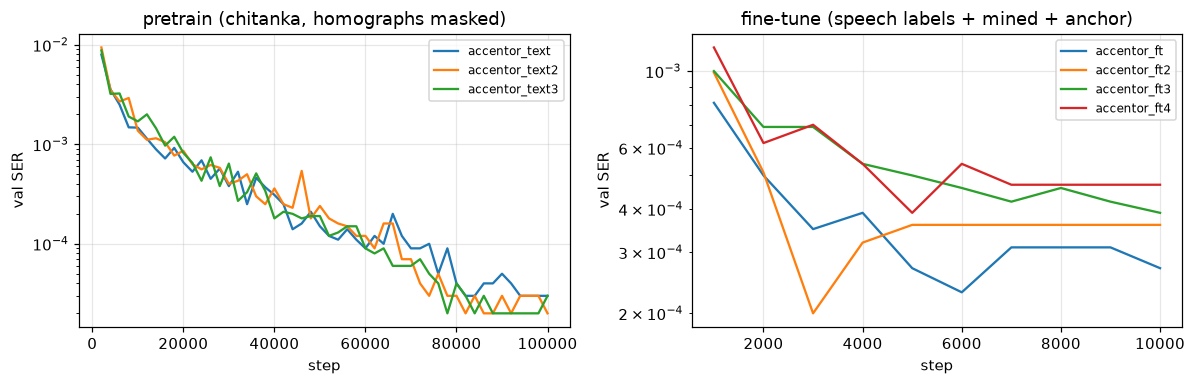

In [6]:
# Figure 1 — validation SER curves (log scale)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for e in ['accentor_text', 'accentor_text2', 'accentor_text3']:
    if e in curves:
        r = curves[e]
        axes[0].plot([x['step'] for x in r], [max(x['ser'], 1e-6) for x in r], label=e)
axes[0].set_title('pretrain (chitanka, homographs masked)')
for e in ['accentor_ft', 'accentor_ft2', 'accentor_ft3', 'accentor_ft4']:
    if e in curves:
        r = curves[e]
        axes[1].plot([x['step'] for x in r], [max(x['ser'], 1e-6) for x in r], label=e)
axes[1].set_title('fine-tune (speech labels + mined + anchor)')
for ax in axes:
    ax.set_yscale('log'); ax.set_xlabel('step'); ax.set_ylabel('val SER')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 6.2 Homograph battery progression

The battery is a native-curated set of 25 sentences covering 13 homograph classes, each sentence forcing one reading by context. The text-only pretrain can learn at most one reading per form, so its score is the structural baseline. (Regenerate any row with `eval_accentor.py --ckpt exp/<run>/best.pt --battery config/bg/homograph_battery_sentences.json`.)

| checkpoint | battery | val SER | what changed |
|---|---|---|---|
| pretrain (text-only) | **11/25** | 0.003% | structural baseline: one reading per form |
| ft1 — three-tier speech labels | **12/25** | 0.023% | every *majority* reading learned at conf 1.00; every failure is a *minority* reading |
| ft2 — +tier-3 -и verbs | **12/25** | 0.020% | чета → 2/2 (≈balanced 19:9 tokens); купи → 0/2 (sparse noisy tokens *inverted* it) |
| ft3 — +both-readings mining | **12/25** | 0.039% | говори (141 mined imp.) & купи (perfective) → 2/2 — first imperative flips; all seven 3sg readings solid; two semantic classes regressed, offsetting |
| ft4 — +balance cap 6:1 | **13/25** | 0.039% | gains held; OOD SER unchanged after a 2000→300 3sg cut; **прави did not flip at 6:1** ⇒ absolute-count wall |

Per-class outcome at ft4: **solved** — all 3sg root readings, чета́/че́та, говори́ (imperative), купи́/ку́пи, вълна́ (wave), боя́, коли́, за́мък; **unsolved** — imperfective imperatives with <100 distinct contexts (прави́, носи́, учи́, ходи́, моли́) and low-coverage semantic homographs (па́ра/пара́, ко́са adj., само́). Reporting rule: quote battery accuracy **split by majority vs minority reading** — the merged number hides exactly the phenomenon under study.


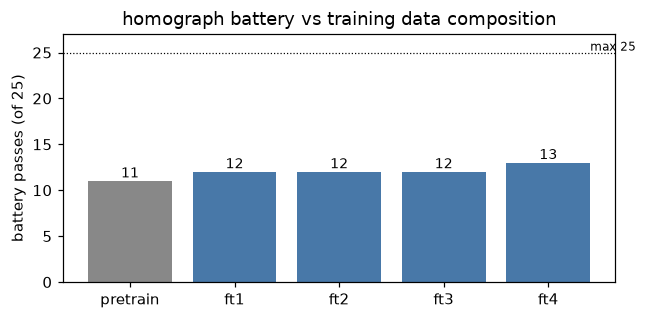

In [7]:
# Figure 2 — battery progression
runs = ['pretrain', 'ft1', 'ft2', 'ft3', 'ft4']
scores = [11, 12, 12, 12, 13]
fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar(runs, scores, color=['#888'] + ['#4878a8'] * 4)
ax.axhline(25, ls=':', c='k', lw=0.8); ax.text(4.4, 25.2, 'max 25', fontsize=8)
ax.set_ylim(0, 27); ax.set_ylabel('battery passes (of 25)')
ax.set_title('homograph battery vs training data composition')
for b, s in zip(bars, scores):
    ax.text(b.get_x() + b.get_width()/2, s + 0.4, str(s), ha='center', fontsize=9)
plt.tight_layout(); plt.show()

In [8]:
# Table 4 — harvested homograph splits: both readings, from audio (live)
# Reproduces the minority-coverage evidence: counts of each marked variant
# chosen by the aligner for the battery homograph words.
WATCH = ['вълна', 'пара', 'чета', 'коса', 'само', 'боя', 'коли',
         'говори', 'носи', 'прави', 'учи', 'ходи', 'моли', 'купи', 'скочи']
counts = {w: collections.Counter() for w in WATCH}
n_read = 0
for p in ['data/kaldi/stress_labels.jsonl', 'data/kaldi/stress_labels_parliament2.jsonl']:
    if not exists(p): continue
    with open(ROOT / p, encoding='utf-8') as f:
        for line in f:
            r = json.loads(line); n_read += 1
            w = r.get('word', '')
            if w in counts:
                counts[w][r.get('marked', '')] += 1
print(f'scanned {n_read:,} aligned tokens (audiobooks + parliament round-2)\n')
print(f"{'word':<10} {'variant counts (aligner-chosen, from audio)'}")
print('─' * 64)
for w in WATCH:
    if counts[w]:
        s = '   '.join(f'{v} ×{c}' for v, c in counts[w].most_common())
        print(f'{w:<10} {s}')

scanned 379,333 aligned tokens (audiobooks + parliament round-2)

word       variant counts (aligner-chosen, from audio)
────────────────────────────────────────────────────────────────
вълна      вълна́ ×35   въ́лна ×22
пара       па́ра ×24   пара́ ×1
чета       чета́ ×19   че́та ×9
коса       коса́ ×94
само       са́мо ×2610   само́ ×36
боя        боя́ ×31   бо́я ×3
коли       коли́ ×27   ко́ли ×1
говори     гово́ри ×250   говори́ ×17   го́вори ×1
носи       но́си ×97   носи́ ×5
прави      пра́ви ×461   прави́ ×13
учи        у́чи ×10   учи́ ×2
ходи       хо́ди ×21   ходи́ ×2
моли       мо́ли ×4
купи       ку́пи ×21   купи́ ×9
скочи      ско́чи ×57


### 6.3 Out-of-domain generalization (parliament stenograms)

The train/val split is all chitanka *fiction*; parliamentary stenograms are formal political speech — different register, vocabulary, and syntax — making them a true generalization probe (`eval_accentor_ood.py`). Two measurements on unseen text:

1. **Automatic OOD SER:** for every *unambiguous* lexicon word in sampled stenogram sentences, compare the model's argmax vowel against the dictionary. Robust to sentence overlap (it scores dictionary words, not memorized sentences); deliberately excludes homographs (no automatic truth without audio).
2. **Homograph-in-the-wild:** model-marked natural sentences containing the homograph verbs, for native review.

| checkpoint | OOD SER | n words | func zero-err | mean conf |
|---|---|---|---|---|
| ft3 | **0.014%** | 14,251 | 0.000% | 1.000 |
| ft4 | **0.021%** | 19,026 | 0.011% (n=17,707) | 1.000 |

Essentially **no degradation from fiction to political speech** (val SER 0.020–0.039% → OOD 0.014–0.021%) — learned lexical stress transfers across register. In-the-wild homograph reads mirror the battery: говори/прави/чета/само/купи contextually correct (including чета́ as verb in "което Ви чета́"); носи/учи show the imperfective-imperative over-final error in the wild too, consistent with the coverage wall. Crucially, ft4's aggressive 3sg down-sampling (2000→300) did **not** move OOD SER — rebalancing is safe for the general lexicon.

### 6.4 Comparison with the reference system

| | Geneva et al. 2023 | this work (ft4) |
|---|---|---|
| aligned speech | 2,695 h (749 h AM) | ~163 h (63 audiobook + 99.7 parliament) |
| annotation AM | TDNN (auto-SER 0.119%) | GMM tri3b (pilot; TDNN at milestone A) |
| pretrain corpus | 48M tokens audiobooks + 22M parliament | 80M tokens chitanka (dictionary-marked) |
| SER (auto) | 0.119% | 0.002% val / 0.014–0.021% OOD¹ |
| homograph eval | (aggregate SER) | battery 13/25, split by reading class |

¹ Not directly comparable: our auto-SER is dictionary-vs-model agreement on unambiguous words, theirs is TDNN-vs-model on all words including homographs. The honest comparison lands at milestone A when the annotation TDNN exists. What *is* new here: the per-reading-class breakdown, the coverage-wall quantification, and the vetting-calibrated tier policy — none reported in the reference.


## 7. Findings

**F1 — The minority-coverage wall.** After ft1, *every* battery failure was the minority reading of its class, with the majority reading at confidence 1.00. Corpus register is the cause: parliamentary and narration speech is overwhelmingly declarative 3rd-person, so imperative readings (говори́!, носи́!) structurally barely occur — the aligner captured every one it heard; the corpus just holds few. **Homograph accuracy is bounded by minority-reading coverage, and register systematically starves specific classes** (here the entire imperative/3sg alternation).

**F2 — The threshold is ~20 distinct balanced contexts per reading.** чета́/че́та, the one ~balanced class (19:9), went from a 0.51 coin-flip to a confident held-out PASS the moment it was supervised (ft2). This number sets the miner's delivery spec, and the admission rule: do not admit a class to tier-3 until it can be populated to that floor.

**F3 — Sparse noisy minority data is worse than none.** купи entered tier-3 with sparse, subtle tokens (aorist vs imperative are segmentally identical) and the model learned both readings *backwards* (1/2 → 0/2), destroying a class that was accidentally right by prior. Label acquisition must be gated on both count *and* precision.

**F4 — The imperative wall is absolute count, not class ratio.** говори flipped with 141 distinct mined imperative contexts while still outnumbered; прави failed with 50 even after rebalancing to 6:1 (ft4). **Reweighting is not new signal.** The lever is more *distinct* minority contexts, not sampling tricks.

**F5 — GMM forced alignment has a systematic final-stress bias on prosodically weak words** — strong enough to invert corpus majorities (може́ 1125:517 vs vetted truth мо́же 0/5). These words genuinely destress/reduce in running speech (the native's 44% "unsure" rate on them is itself signal), so a forced binary label there is partly meaningless. Consequences: the tier-2 exclusion list, and a ready-made regression test for the annotation TDNN — its counts for може/всички/съюз must flip to the canonical majority, or it inherited the bias.

**F6 — Synthetic speech cannot label homographs.** BgTTS-38M, probed as a stress oracle, chose the frequency-prior reading regardless of context, consistently across seeds. Any TTS trained on unmarked text has *internalized* the prior we are trying to overcome; using it for labels is circular.

**F7 — Curated function words must outrank the dictionary.** rechko carries stressed clitic entries (и́, му́) that are wrong in running text; letting them through produced spurious clitic stress measurable in `zero_err`. The fix (curated list takes precedence) drove zero_err to 0.000% — and doubles as an example of why `zero_err` must be reported separately from SER.

**F8 — Cross-domain alignment needs one in-domain bootstrap round.** Audiobook-seeded segmentation of parliament yielded 20% with 10–35% label noise; one bootstrap iteration (retrain GMMs on audiobooks + round-1 segments, re-segment, re-align) recovered **79% yield at 0.5–6.4% noise**. This is the transferable recipe for any new acoustic domain.

**F9 — TTS marking consistency.** A TTS fine-tuned on marks that contradict its training audio learns a noisy mark→stress mapping — the stress *moves* under a mark, but incorrectly. Re-marking the training text with the deployed Accentor version fixed the imperative case audibly (§8). Corollary: every Accentor upgrade entails a TTS re-fine-tune (cheap: text side only, audio tokens reused).


## 8. End-to-end TTS evaluation

The full relay was exercised twice on the combined corpus (audiobook narrator + 50 h audiobook-clip slice):

- **Phase A (old marks — the control, inadvertently).** OmniVoice-BG fine-tuned on text marked by an early Accentor whose errors contradicted the audio (като́ vs the narrator's ка́то). Listening result: the model **does obey U+0301** (moving the mark audibly moves the stress) but renders it incorrectly — direct audible evidence of F9.
- **Phase B (re-marked with ft4, `mark_tts_txts.py`, re-fine-tuned = `exp/omnivoice_bg_ft4`).** The minimal-pair test *"Той гово́ри тихо."* / *"Говори́ по-високо!"*: the imperative говори́ now renders **correctly with clear final stress**; the 3sg reading shows a residual off-by-one-vowel error (го́вори for гово́ри) — placement is right in the *text*, the acoustic rendering is imprecise, consistent with limited fine-tune audio rather than front-end error.

**Planned formal protocol (TODO before submission):** minimal-pair intelligibility test (N homograph pairs × 2 readings, native forced-choice identification of intended reading from audio alone), plus standard MOS, plus the automatic verifier battery of §10 (aligner-measured stress obedience, Whisper CER, speaker similarity, UTMOS).

**Serving.** `serve.py` hosts the relay behind `POST /synth` (FastAPI, LAN): plain text → Accentor (`--accentor`, CPU, few ms) → marked text → OmniVoice-BG (GPU, fixed-reference deterministic cloning, seeded) → 24 kHz WAV. `/health` reports the active `accent_frontend`. The TrainGen video generator consumes it as a thin client.


## 9. Limitations

1. **GMM-grade labels.** All current speech labels come from the pilot GMM aligner; the paper's trusted annotator is a TDNN (auto-SER 0.119%). Tier policy contains the damage but cannot recover tier-2 words. Milestone A replaces this.
2. **Scale.** ~163 aligned hours vs the reference's 2,695; low-frequency homograph classes (моли́: 0 tokens) are simply unobserved.
3. **Semantic homographs remain data-bound.** Mining (C4) covers only the morphologically regular alternation; въ́лна/вълна́-type pairs need speech volume.
4. **The battery is small** (25 sentences) — a per-class diagnostic, not a statistical benchmark. The in-the-wild protocol scales it but requires native review.
5. **OOD SER measures dictionary agreement**, so it inherits dictionary errors and excludes homographs by construction; it is a transfer probe, not an absolute accuracy.
6. **Single-voice TTS evaluation.** Phase-B listening is one narrator; stress-rendering fidelity under zero-shot cloning of arbitrary voices is untested.
7. **Text normalization is out of scope** — numbers/dates in stenograms are dropped (their audio regions are discarded at segmentation), and the serving path does not verbalize numerals.


## 10. Future work

- **Milestone A (~500 h raw parliament):** annotation TDNN on audiobooks + parliament (≈ the paper's 749 h recipe), with the F5 bias test as its acceptance gate; then per-sentence stress decoding over the whole corpus → BG-PARLAMA-scale label set; 400 h audiobook ingest (in progress) adds narrated *dialogue* — the register that carries spoken imperatives.
- **Class-balanced sampling** once mining + milestone A provide enough distinct minority contexts for upweighting to generalize (F4 gate).
- **Preference-optimization polish for the TTS** (explored, deliberately sequenced last): the project already owns automatic verifiers — the stress-aware aligner (does the audio realize its marks?), Whisper CER, speaker similarity, UTMOS — so the practical form is RLAIF, not RLHF. Ladder: best-of-N at inference (ships anytime, zero training) → best-of-N distillation / RAFT (reuses the ordinary trainer; the recommended target) → Diffusion-DPO variants (log-probs are intractable in a mask-prediction LM; ELBO proxy needed) → online PPO/GRPO (rejected on 16 GB hardware). Principle: *humans calibrate verifiers; machines scale supervision* — RL polishes residuals only after the supervised loop lands.
- **Release:** candidates lexicon, battery, mined contexts, label-harvest tooling, and the Accentor checkpoints, license permitting (rechko terms to verify).


## 11. Reproducibility

**Hardware.** Single workstation: 24 cores, 60 GB RAM (+8 GB swap), one 16 GB GPU, NVMe. Every stage fits; the constraints are themselves documented findings (vocab-limited lexicon compilation after an OOM that masqueraded as a power failure; `seg_nj=8` for segmentation memory; `expandable_segments` for the TTS fine-tune).

**Pipeline commands (one line per stage).**

```bash
# 1. lexicon: rechko dump -> candidates DB -> stress-aware phonetic lexicon
python build_bg_lexicon.py --dump ../rechko/db.sql --out data/bg_lexicon/bg_stress.sqlite
python build_stress_candidates.py --src ... --battery config/bg/homograph_battery.json --out ... --validate
python build_lexicon_phones.py --cand ... --out-lexicon data/bg_lexicon/lexicon_full.txt

# 2. pretrain corpus
python prep_chitanka.py --archive data/chitanka_archive --out data/chitanka
python mark_chitanka_text.py --corpus data/chitanka --sqlite ...candidates.sqlite --out data/chitanka/marked.jsonl

# 3. Accentor pretrain (~4.6 h, 16 GB GPU)
python train_accentor.py --data data/chitanka/marked.jsonl --out exp/accentor_text3

# 4. corpora: parliament crawl + audiobook ingest
python prep_bg_parliament.py --out data/bg_parliament --date-start 2020-01-01 --date-end 2026-12-31 --reverse
python prep_bg400.py --out data/bg400 --max-hours 500

# 5. stress-aware alignment + label harvest
KALDI_ROOT=~/kaldi bash kaldi_pilot.sh                 # audiobooks: GMM ladder + align
KALDI_ROOT=~/kaldi bash kaldi_parliament_pilot.sh      # parliament: segment + bootstrap + align
python harvest_stress_labels.py --pilot exp/kaldi_pilot --ali exp/tri3b_ali --out data/kaldi/stress_labels.jsonl

# 6. vet, mine, fine-tune, evaluate
python vet_stress_cli.py --labels data/kaldi/stress_labels_parliament2.jsonl   # native audit
python mine_homographs.py --corpus data/chitanka --verbs config/bg/homograph_verbs.json --out data/chitanka/homograph_contexts.jsonl
python build_accentor_finetune.py --labels ... --extra-marked ... --mix-chitanka ... --balance-ratio 4 --balance-floor 300 --out data/accentor_finetune.jsonl
python train_accentor.py --data data/accentor_finetune.jsonl --init exp/accentor_text3/best.pt --out exp/accentor_ft4 --steps 10000 --lr 1e-4
python eval_accentor.py --ckpt exp/accentor_ft4/best.pt --battery config/bg/homograph_battery_sentences.json
python eval_accentor_ood.py --ckpt exp/accentor_ft4/best.pt --transcripts data/bg_parliament/transcripts --n 4000

# 7. TTS: re-mark training text with the deployed Accentor, re-fine-tune, serve
python mark_tts_txts.py --ckpt exp/accentor_ft4/best.pt --dirs data/bg/tokens/train data/bg/tokens/dev ...
accelerate launch --gpu_ids 0 --num_processes 1 -m omnivoice.cli.train --train_config config/bg/train_config_bg_marked.json ...
python -m omnivoice.cli.serve --model models/omnivoice-bg --accentor exp/accentor_ft4/best.pt --host 0.0.0.0 --port 8002 --seed 42
```

**Key repository files.**

| Component | Files |
|---|---|
| Lexicon | `build_bg_lexicon.py`, `build_stress_candidates.py`, `build_lexicon_phones.py`, `config/bg/always_final_imperatives.json` |
| Corpus + marking | `prep_chitanka.py`, `mark_chitanka_text.py`, `prep_bg_parliament.py`, `bg_sten_clean.py`, `prep_bg400.py` |
| Accentor | `accentor_model.py`, `train_accentor.py`, `eval_accentor.py`, `eval_accentor_ood.py` |
| Alignment + labels | `prep_kaldi_data.py`, `kaldi_pilot.sh`, `kaldi_parliament_pilot.sh`, `harvest_stress_labels.py`, `vet_stress_cli.py` |
| Mining + fine-tune | `mine_homographs.py`, `config/bg/homograph_verbs.json`, `build_accentor_finetune.py` |
| TTS + serving | `mark_tts_txts.py`, `omnivoice/cli/serve.py`, `serve_bg.sh`, `eval_bg_ab.py` |
| Curation (native) | `config/bg/homograph_battery*.json`, `config/bg/function_words_unstressed.json`, `config/bg/lexicon_supplement.json` |

**Operational lessons** (full detail in `docs/BG_PIPELINE_GUIDE.md` §Pitfalls): budget `nj × per-job RSS` against RAM before any fan-out (an OOM kill of the desktop session is indistinguishable from a power failure until you read `journalctl`); `prons.*.gz` are only valid against the symbol tables they were written with (the harvester guards at >10% mismatch); never seek session FLACs with ffplay (no seektable — extract with ffmpeg, play via paplay).


## 12. References *(complete before submission)*

1. **Geneva et al., Interspeech 2023** — the Accentor: contextual lexical-stress prediction for Bulgarian; source of the architecture, the alignment-labeling method, and BG-PARLAMA. *(exact title/authors from `docs/interspeech2023.pdf`)*
2. **Virkkunen et al., 2022** — Finnish Parliament ASR corpus pipeline, arXiv:2203.14876 — reference for transcript-biased long-audio segmentation of plenary recordings.
3. **OmniVoice** (k2-fsa) — massively multilingual zero-shot TTS; diffusion-LM over audio codec tokens. https://github.com/k2-fsa/OmniVoice
4. **Higgs Audio V2** — neural audio codec/tokenizer (8 codebooks, 24 kHz).
5. **Qwen3-0.6B** — text-LLM backbone of OmniVoice.
6. **Povey et al., 2011** — The Kaldi speech recognition toolkit, ASRU.
7. **Peddinti/Manohar et al.** — Kaldi `segment_long_utterances` / data-cleanup recipes for lightly-supervised alignment.
8. **rechko / chitanka** — Bulgarian dictionary (lemma stress) and digital library (text corpus). License terms to verify before artifact release.
9. **BgTTS-38M-V2** (beleata74) — compact end-to-end Bulgarian TTS; used here only as a negative-control stress oracle (F6).
10. **Ren et al., 2019/2021 — FastSpeech 1/2** — origin of the FFT-block architecture.
11. **RAFT / DPO / Diffusion-DPO** — preference-optimization methods surveyed for the planned TTS polish (§10).
